# Campagne de tests du 8311 sur le 8743-CL : à vide, puis en charge

La **même suite de tests** tourne deux fois : moteur libre (partie A), puis moteur monté sur la platine (partie B). La dernière cellule compare les erreurs selon la vitesse et selon la distance.

**Les deux tests**
1. *Aller-retour en boucle ouverte* : recul de `d`, puis retour de `d`. On relève l'écart de chaque jambe (déplacement lu par le codeur moins déplacement demandé), l'écart de fermeture (position de fin moins position de départ) et la vitesse mesurée.
2. *`goto` en boucle fermée* : de A à B, puis de B à A, comme dans l'usage réel. On relève l'écart d'arrivée à chaque point.

**Sens** : le recul s'éloigne de la platine, le retour la repousse. Le 8311 a 12,7 mm de course : la référence doit être posée avec **plus de 1,2 mm de course libre derrière** et 0,1 mm devant.

**Sûreté**
- Bouton Stop (carré) du notebook : arrête le moteur. Limites logicielles posées autour de la référence.
- Le moteur ne doit pas pousser plus de **22 N** (5 lb). Surface plane et dure, jamais un cône ni un V.
- Les résultats sont écrits dans `resultats_picomoteurs.json` après chaque test : on peut interrompre et relancer la même cellule, elle reprend. Supprimer ce fichier pour recommencer.
- La dernière cellule est l'analyse. `pico.close()` (avant elle) libère l'USB.

In [1]:
# Cellule 1 : charger le moteur
import os, sys
sys.path.insert(0, os.getcwd())

from qcodes.instrument import Instrument
from newport_picomotors import connect_8743

Instrument.close_all()                 # permet de relancer cette cellule sans erreur de nom
pico = connect_8743("pico", allow_motion=True, positions_file="positions_campagne.json")
ax = pico.axis1                        # le 8311
print(pico.get_idn())
ax.where()

Connected to: New_Focus 8743-CL (serial:13097, firmware:4.06) in 1.16s
{'vendor': 'New_Focus', 'model': '8743-CL', 'firmware': '4.06', 'serial': '13097'}


{'counts': 0,
 'um_depuis_reference': None,
 'reference_valide': False,
 'en_mouvement': False,
 'boucle_fermee': 0,
 'vitesse_VA': 2000,
 'positions_proches': []}

## Plan des tests

Modifie les listes ci-dessous si besoin. Les distances courtes sont faites à toutes les vitesses (comparaison équilibrée selon la vitesse). Les distances longues le sont seulement aux vitesses assez grandes pour durer moins de deux minutes par jambe. Vitesse nominale : 0,0293 µm/s par unité de `VA`.

In [2]:
import json, time
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt

UM = 0.0496                                          # µm par comptage
FICHIER_RESULTATS = "resultats_picomoteurs.json"
V_UM_S_PAR_VA = 0.0293                               # vitesse nominale : µm/s par unité de VA

VA_LISTE = [100, 300, 600, 1000]                     # VA : environ 3, 9, 18 et 29 µm/s
DIST_COURTES_UM = [20, 50, 100]                      # à toutes les vitesses
DIST_LONGUES_UM = {300: [500], 600: [500, 1000], 1000: [500, 1000]}
REPETITIONS = 2                                      # répétitions du test aller-retour
GOTO_COMBOS = [(300, 100), (300, 500), (1000, 100), (1000, 500)]     # (VA, distance A-B en µm)
MARGE_ARRIERE_UM, MARGE_AVANT_UM = 1100, 100         # limites logicielles autour de la référence

def construire_plan():
    plan = []
    for rep in range(1, REPETITIONS + 1):
        for va in VA_LISTE:
            for d in DIST_COURTES_UM + DIST_LONGUES_UM.get(va, []):
                plan.append({"id": f"rt_{va}_{d}_{rep}", "type": "rt", "va": va, "distance_um": d, "rep": rep})
    for va, d in GOTO_COMBOS:
        plan.append({"id": f"goto_{va}_{d}_1", "type": "goto", "va": va, "distance_um": d, "rep": 1})
    return plan

def duree_estimee(t):
    v = V_UM_S_PAR_VA * t["va"]
    return (2 * t["distance_um"] / v + 10) if t["type"] == "rt" else ((2 * t["distance_um"] + 25) / v + 20)

plan = construire_plan()
print(f"{len(plan)} tests par condition, durée estimée {sum(map(duree_estimee, plan)) / 60:.0f} minutes")
print("VA    vitesse     distances (µm)")
for va in VA_LISTE:
    print(f"{va:<5d} {V_UM_S_PAR_VA * va:5.1f} µm/s  {DIST_COURTES_UM + DIST_LONGUES_UM.get(va, [])}")
print("goto A<->B (VA, µm) :", GOTO_COMBOS)

38 tests par condition, durée estimée 29 minutes
VA    vitesse     distances (µm)
100     2.9 µm/s  [20, 50, 100]
300     8.8 µm/s  [20, 50, 100, 500]
600    17.6 µm/s  [20, 50, 100, 500, 1000]
1000   29.3 µm/s  [20, 50, 100, 500, 1000]
goto A<->B (VA, µm) : [(300, 100), (300, 500), (1000, 100), (1000, 500)]


In [3]:
# Fonctions de mesure, d'enregistrement et d'exécution du plan
def suivre(distance_um, va):
    '''Déplacement relatif avec relevé de TP : résultat, temps (s), positions (µm depuis le départ).'''
    r = ax.move(distance_um, speed=va, unit="um", trace=True)
    t = np.array([p[0] for p in r["trace"]], float)
    x = (np.array([p[1] for p in r["trace"]], float) - r["TP_avant"]) * UM
    return r, t, x

def vitesse(t, x):
    '''Vitesse moyenne en µm/s entre 10 % et 90 % du déplacement, ou None s'il y a trop peu de points.'''
    total = x[-1] - x[0]
    if abs(total) < 1e-9 or len(t) < 4:
        return None
    frac = (x - x[0]) / total
    sel = (frac > 0.1) & (frac < 0.9)
    if sel.sum() < 2 or np.ptp(t[sel]) <= 0:
        return None
    return abs(float(np.polyfit(t[sel], x[sel], 1)[0]))

def charger():
    if not os.path.exists(FICHIER_RESULTATS):
        return []
    with open(FICHIER_RESULTATS, encoding="utf-8") as f:
        return json.load(f)

def enregistrer(rec):
    donnees = charger()
    donnees.append(rec)
    tmp = FICHIER_RESULTATS + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(donnees, f, ensure_ascii=False, indent=1)
    os.replace(tmp, FICHIER_RESULTATS)

def faits(condition):
    return {r["id"] for r in charger() if r["condition"] == condition and "erreur" not in r}

def ref_counts():
    return ax.positions()["REF"]["counts"]

def test_rt(cond, t):
    '''Aller-retour : recul de d, puis retour de d (boucle ouverte).'''
    d, va = t["distance_um"], t["va"]
    tp0 = ax.position()
    r1, t1, x1 = suivre(-d, va)
    r2, t2, x2 = suivre(+d, va)
    return {"condition": cond, **t, "date": datetime.now().isoformat(timespec="seconds"),
            "derive_depart_comptes": tp0 - ref_counts(),
            "recul_demande": r1["demande_comptes"], "recul_ecart": r1["ecart_comptes"],
            "retour_ecart": r2["ecart_comptes"], "fermeture_comptes": r2["TP_apres"] - tp0,
            "vitesse_recul_um_s": vitesse(t1, x1), "vitesse_retour_um_s": vitesse(t2, x2),
            "duree_recul_s": r1["duree_s"], "duree_retour_s": r2["duree_s"]}

def test_goto(cond, t):
    '''De A (la référence) à B (d en arrière), puis retour en A, par goto en boucle fermée.'''
    d, va = t["distance_um"], t["va"]
    a = ref_counts()
    b = a - round(d / UM)
    rb = ax.goto(b, speed=va)
    ra = ax.goto("REF", speed=va)
    return {"condition": cond, **t, "date": datetime.now().isoformat(timespec="seconds"),
            "ecart_B": rb["ecart_comptes"], "ecart_A": ra["ecart_comptes"],
            "duree_B_s": rb["duree_s"], "duree_A_s": ra["duree_s"]}

def executer_plan(cond):
    '''Exécute les tests du plan pas encore faits pour cette condition ; écrit chaque résultat ; reprend après une interruption.'''
    reste = [t for t in construire_plan() if t["id"] not in faits(cond)]
    print(f"Condition '{cond}' : {len(reste)} tests à faire, environ {sum(map(duree_estimee, reste)) / 60:.0f} minutes.")
    if reste:
        ax.goto("REF", speed=300)                    # point de départ commun, utile après une interruption
    debut = time.time()
    for k, t in enumerate(reste, 1):
        try:
            rec = (test_rt if t["type"] == "rt" else test_goto)(cond, t)
        except Exception as exc:
            enregistrer({"condition": cond, **t, "erreur": str(exc)})
            print(f"ARRÊT sur {t['id']} : {exc}")
            return
        enregistrer(rec)
        if t["type"] == "rt":
            resume = f"fermeture {rec['fermeture_comptes']:+d}, recul {rec['recul_ecart']:+d}, retour {rec['retour_ecart']:+d} comptes"
        else:
            resume = f"écart en B {rec['ecart_B']:+d}, en A {rec['ecart_A']:+d} comptes"
        print(f"[{k}/{len(reste)}] {t['id']:<16} {resume}   ({(time.time() - debut) / 60:.1f} min)")
    ax.goto("REF", speed=300)
    print("Terminé.")

## Partie A : à vide

Le moteur est libre, rien ne pousse. Il est en milieu de course, avec plus de 1,2 mm de course libre derrière. La cellule pose la référence à la position actuelle et les limites autour.

In [4]:
CONDITION = "vide"
ax.set_reference(force=True)
ax.mark("REF")
ax.set_limits(-MARGE_ARRIERE_UM, MARGE_AVANT_UM)
print(ax.where())

{'counts': 1000000, 'um_depuis_reference': 0.0, 'reference_valide': True, 'en_mouvement': False, 'boucle_fermee': 0, 'vitesse_VA': 2000, 'positions_proches': ['REF']}


In [5]:
executer_plan("vide")

Condition 'vide' : 38 tests à faire, environ 29 minutes.
[1/38] rt_100_20_1      fermeture +0, recul +0, retour +0 comptes   (0.3 min)
[2/38] rt_100_50_1      fermeture +0, recul +0, retour +0 comptes   (0.8 min)
[3/38] rt_100_100_1     fermeture +0, recul +1, retour -1 comptes   (2.0 min)
[4/38] rt_300_20_1      fermeture +0, recul +0, retour +0 comptes   (2.1 min)
[5/38] rt_300_50_1      fermeture +0, recul +1, retour +0 comptes   (2.3 min)
[6/38] rt_300_100_1     fermeture +0, recul +0, retour +0 comptes   (2.8 min)
[7/38] rt_300_500_1     fermeture +0, recul +0, retour +0 comptes   (4.6 min)
[8/38] rt_600_20_1      fermeture +0, recul +0, retour +0 comptes   (4.7 min)
[9/38] rt_600_50_1      fermeture +0, recul +0, retour +0 comptes   (4.8 min)
[10/38] rt_600_100_1     fermeture -1, recul +0, retour -1 comptes   (5.1 min)
[11/38] rt_600_500_1     fermeture +1, recul +1, retour +0 comptes   (6.0 min)
[12/38] rt_600_1000_1    fermeture +0, recul +0, retour +0 comptes   (7.9 min)
[13/

## Partie B : en charge

1. Monte le moteur sur la platine, en milieu de course, avec plus de 1,2 mm de course libre derrière lui. **Contrôleur allumé** : le codeur compte la vis, la référence sera reposée.
2. Vérifie la liste de sûreté du haut : moins de 22 N, surface plane et dure, aucune butée franche.
3. Approche à la main jusqu'au contact (cellule suivante). `PRECHARGE_UM` : poussée supplémentaire au contact avant de poser la référence. 0 par défaut ; une platine sans ressort de rappel n'est chargée qu'avec une précharge. Reste largement sous 22 N.
4. `NOTE_CHARGE` : décris le montage, il est enregistré avec les résultats.

In [6]:
# 1. Approche lente jusqu'au contact. Entrée : +2 µm, c : contact atteint, q : arrêter
total = 0
while total < 500:
    rep = input(f"Approche ({total} µm faits). Entrée : +2 µm, c : contact atteint, q : arrêter  ").strip().lower()
    if rep in ("c", "q"):
        print("Contact noté." if rep == "c" else "Approche arrêtée.")
        break
    ax.nudge(1, steps=round(2 / (pico.increment * UM)), speed="lent")       # environ 2 µm
    total += 2
else:
    print("500 µm sans contact : arrêt de sécurité.")

Approche (0 µm faits). Entrée : +2 µm, c : contact atteint, q : arrêter   c


Contact noté.


In [7]:
CONDITION = "charge"
PRECHARGE_UM = 0                                  # µm de poussée supplémentaire avant la référence
NOTE_CHARGE = "décris ici la platine, le ressort de rappel, la force estimée"
if PRECHARGE_UM:
    ax.move(PRECHARGE_UM, speed="lent", unit="um")
ax.set_limits(None, None)
ax.set_reference(force=True)
ax.mark("REF")
ax.set_limits(-MARGE_ARRIERE_UM, MARGE_AVANT_UM)
enregistrer({"condition": "charge", "id": "note", "type": "note", "note": NOTE_CHARGE, "precharge_um": PRECHARGE_UM,
             "date": datetime.now().isoformat(timespec="seconds")})
print(ax.where())

{'counts': 1000000, 'um_depuis_reference': 0.0, 'reference_valide': True, 'en_mouvement': False, 'boucle_fermee': 0, 'vitesse_VA': 1000, 'positions_proches': ['REF']}


In [8]:
executer_plan("charge")

Condition 'charge' : 38 tests à faire, environ 29 minutes.
[1/38] rt_100_20_1      fermeture +0, recul +0, retour +0 comptes   (0.3 min)
[2/38] rt_100_50_1      fermeture +0, recul +1, retour -1 comptes   (1.0 min)
[3/38] rt_100_100_1     fermeture +0, recul +0, retour +0 comptes   (2.4 min)
[4/38] rt_300_20_1      fermeture +0, recul +1, retour -1 comptes   (2.5 min)
[5/38] rt_300_50_1      fermeture +0, recul +0, retour +0 comptes   (2.8 min)
[6/38] rt_300_100_1     fermeture -1, recul +0, retour -1 comptes   (3.3 min)
[7/38] rt_300_500_1     fermeture +1, recul +1, retour +0 comptes   (5.5 min)
[8/38] rt_600_20_1      fermeture +0, recul +0, retour +0 comptes   (5.6 min)
[9/38] rt_600_50_1      fermeture -1, recul +1, retour -2 comptes   (5.8 min)
[10/38] rt_600_100_1     fermeture +1, recul +2, retour -1 comptes   (6.1 min)
[11/38] rt_600_500_1     fermeture -1, recul +0, retour -1 comptes   (7.3 min)
[12/38] rt_600_1000_1    fermeture +1, recul +2, retour -1 comptes   (9.5 min)
[1

## Fin des mesures

Libère l'USB et retire les limites. Pour mesurer encore, relancer la cellule 1.

In [9]:
ax.set_limits(None, None)
pico.close()

Conditions présentes : ['charge', 'vide']


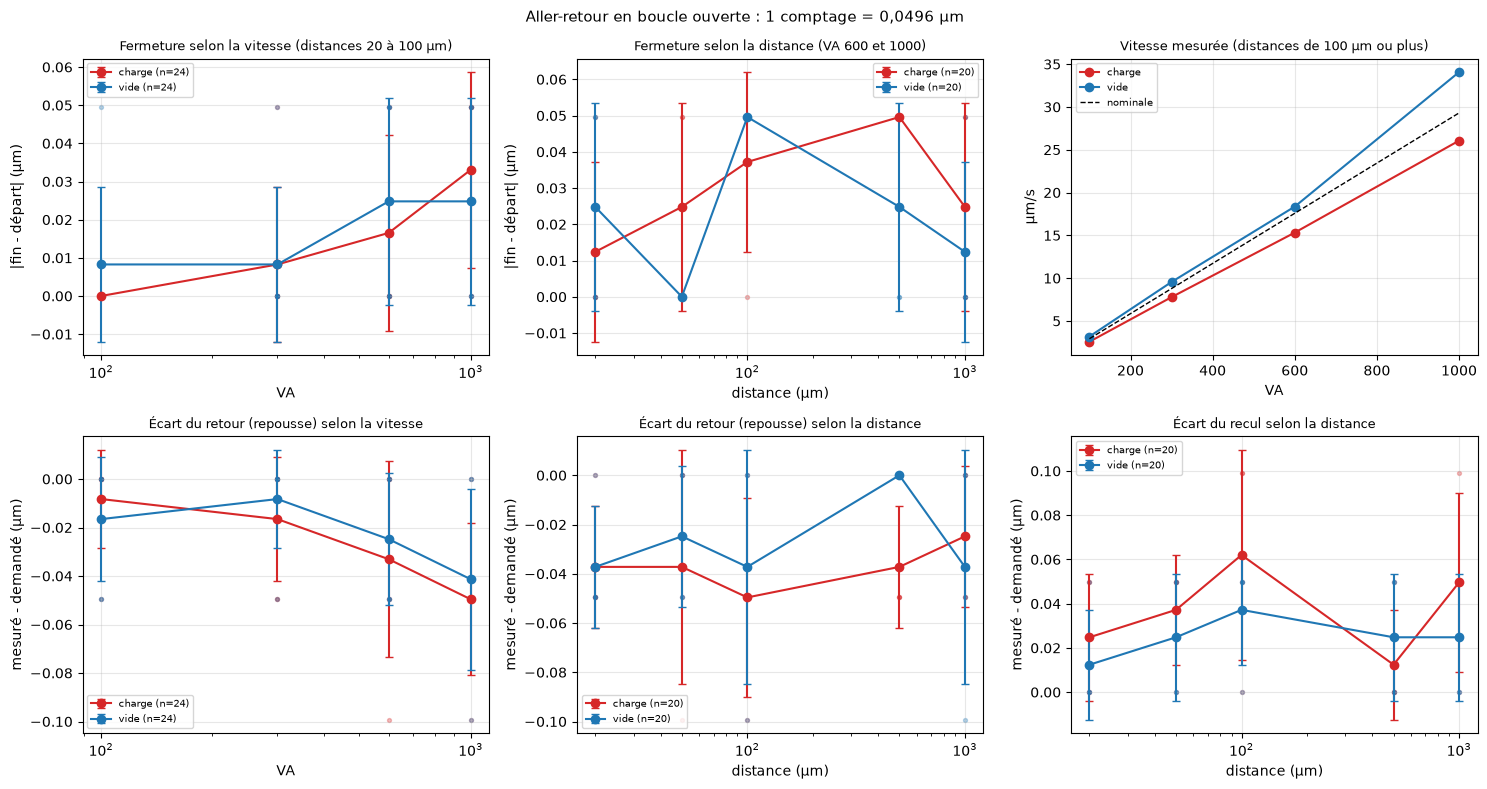


Par vitesse (moyenne sur les distances 20 à 100 µm) :
                fermeture_um  ecart_recul_um  ecart_retour_um  vitesse_um_s
condition va                                                               
charge    100          0.000           0.008           -0.008         2.618
          300          0.008           0.008           -0.017         8.031
          600          0.017           0.033           -0.033        15.782
          1000         0.033           0.050           -0.050        25.852
vide      100          0.008           0.025           -0.017         3.193
          300          0.008           0.008           -0.008         9.637
          600          0.025           0.017           -0.025        18.694
          1000         0.025           0.033           -0.041        34.766

Par distance (moyenne sur VA 600 et 1000) :
                       fermeture_um  ecart_recul_um  ecart_retour_um  vitesse_um_s
condition distance_um                                    

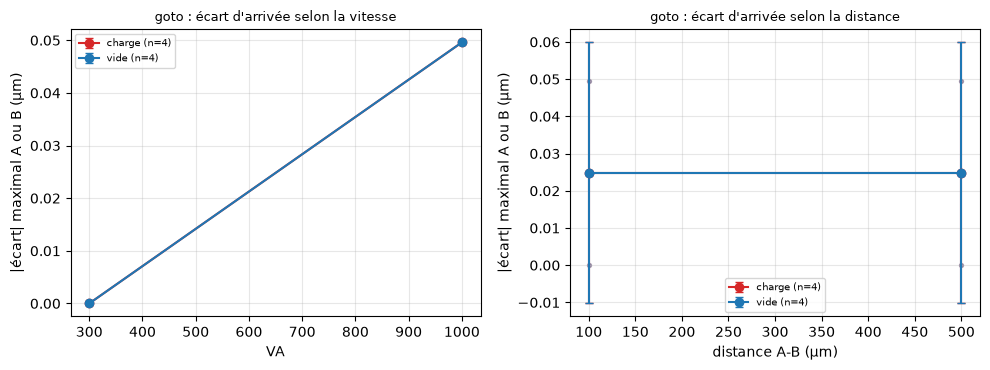


goto en boucle fermée, écarts d'arrivée (comptes) :
                            ecart_B  ecart_A
condition va   distance_um                  
charge    300  100              0.0      0.0
               500              0.0      0.0
          1000 100              0.0     -1.0
               500             -1.0      0.0
vide      300  100              0.0      0.0
               500              0.0      0.0
          1000 100              0.0     -1.0
               500              0.0     -1.0

Montage en charge (2026-10-23T16:58:37) : décris ici la platine, le ressort de rappel, la force estimée ; précharge 0 µm


In [10]:
# Analyse : erreurs selon la vitesse et selon la distance, à vide et en charge
import pandas as pd

tout = charger()
echecs = [r for r in tout if "erreur" in r]
for r in echecs:
    print(f"Test en erreur ({r['condition']}, {r['id']}) : {r['erreur']}")
ok = [r for r in tout if "erreur" not in r and r["type"] in ("rt", "goto")]
rt = pd.DataFrame([r for r in ok if r["type"] == "rt"])
gt = pd.DataFrame([r for r in ok if r["type"] == "goto"])
couleurs = {"vide": "tab:blue", "charge": "tab:red"}
print("Conditions présentes :", sorted(set(rt["condition"])) if not rt.empty else "aucune")

def courbe(a, df, x, y, titre, xlabel, ylabel, log=False):
    for cond, g in df.groupby("condition"):
        m = g.groupby(x)[y].agg(["mean", "std", "count"]).reset_index()
        a.errorbar(m[x], m["mean"], yerr=m["std"].fillna(0), marker="o", capsize=3, color=couleurs.get(cond),
                   label=f"{cond} (n={int(m['count'].sum())})")
        a.scatter(g[x], g[y], s=8, alpha=0.3, color=couleurs.get(cond))
    a.set_title(titre, fontsize=9); a.set_xlabel(xlabel); a.set_ylabel(ylabel); a.grid(alpha=0.3); a.legend(fontsize=7)
    if log:
        a.set_xscale("log")

if rt.empty:
    print("Aucun résultat : lance la partie A, puis la partie B.")
else:
    rt["fermeture_um"] = rt["fermeture_comptes"].abs() * UM                    # |fin - départ|
    rt["ecart_recul_um"] = rt["recul_ecart"] * UM                              # signé
    rt["ecart_retour_um"] = rt["retour_ecart"] * UM                            # signé : jambe qui repousse la platine
    rt["vitesse_um_s"] = rt[["vitesse_recul_um_s", "vitesse_retour_um_s"]].mean(axis=1)
    courtes = rt[rt["distance_um"].isin(DIST_COURTES_UM)]                      # toutes les vitesses : comparaison équilibrée
    rapides = rt[rt["va"] >= 600]                                              # toutes les distances

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    courbe(axes[0, 0], courtes, "va", "fermeture_um", "Fermeture selon la vitesse (distances 20 à 100 µm)", "VA", "|fin - départ| (µm)", log=True)
    courbe(axes[0, 1], rapides, "distance_um", "fermeture_um", "Fermeture selon la distance (VA 600 et 1000)", "distance (µm)", "|fin - départ| (µm)", log=True)
    for cond, g in rt[rt["distance_um"] >= 100].groupby("condition"):      # trop peu de points sur les trajets plus courts
        m = g.groupby("va")["vitesse_um_s"].mean()
        axes[0, 2].plot(m.index, m.values, marker="o", color=couleurs.get(cond), label=cond)
    axes[0, 2].plot(VA_LISTE, [V_UM_S_PAR_VA * v for v in VA_LISTE], "k--", lw=1, label="nominale")
    axes[0, 2].set_title("Vitesse mesurée (distances de 100 µm ou plus)", fontsize=9); axes[0, 2].set_xlabel("VA"); axes[0, 2].set_ylabel("µm/s")
    axes[0, 2].grid(alpha=0.3); axes[0, 2].legend(fontsize=7)
    courbe(axes[1, 0], courtes, "va", "ecart_retour_um", "Écart du retour (repousse) selon la vitesse", "VA", "mesuré - demandé (µm)", log=True)
    courbe(axes[1, 1], rapides, "distance_um", "ecart_retour_um", "Écart du retour (repousse) selon la distance", "distance (µm)", "mesuré - demandé (µm)", log=True)
    courbe(axes[1, 2], rapides, "distance_um", "ecart_recul_um", "Écart du recul selon la distance", "distance (µm)", "mesuré - demandé (µm)", log=True)
    fig.suptitle("Aller-retour en boucle ouverte : 1 comptage = 0,0496 µm", fontsize=11)
    fig.tight_layout(); plt.show()

    colonnes = ["fermeture_um", "ecart_recul_um", "ecart_retour_um", "vitesse_um_s"]
    print("\nPar vitesse (moyenne sur les distances 20 à 100 µm) :")
    print(courtes.groupby(["condition", "va"])[colonnes].mean().round(3).to_string())
    print("\nPar distance (moyenne sur VA 600 et 1000) :")
    print(rapides.groupby(["condition", "distance_um"])[colonnes].mean().round(3).to_string())
    print("\nDérive de la position de départ par rapport à la référence (comptes), maximum par condition :")
    print(rt.groupby("condition")["derive_depart_comptes"].agg(lambda s: int(s.abs().max())).to_string())

if not gt.empty:
    gt["ecart_B_um"], gt["ecart_A_um"] = gt["ecart_B"].abs() * UM, gt["ecart_A"].abs() * UM
    gt["arrivee_um"] = gt[["ecart_B_um", "ecart_A_um"]].max(axis=1)
    fig2, axes2 = plt.subplots(1, 2, figsize=(10, 3.8))
    courbe(axes2[0], gt, "va", "arrivee_um", "goto : écart d'arrivée selon la vitesse", "VA", "|écart| maximal A ou B (µm)")
    courbe(axes2[1], gt, "distance_um", "arrivee_um", "goto : écart d'arrivée selon la distance", "distance A-B (µm)", "|écart| maximal A ou B (µm)")
    fig2.tight_layout(); plt.show()
    print("\ngoto en boucle fermée, écarts d'arrivée (comptes) :")
    print(gt.groupby(["condition", "va", "distance_um"])[["ecart_B", "ecart_A"]].mean().round(2).to_string())
notes = [r for r in tout if r.get("type") == "note"]
for n in notes:
    print(f"\nMontage en charge ({n['date']}) : {n['note']} ; précharge {n['precharge_um']} µm")